# Previsão da seca do Rio Negro em Manaus — jul–dez/2024

**Hackathon Ocean (Samsung Ocean / UEA).** Previsão diária da cota de 01/07 a 31/12/2024 usando apenas informação publicada até **30/06/2024**.

**Modelo em uma frase:** partimos da curva média de vazante dos últimos 15 anos e a deslocamos para cima ou para baixo com três regressões lineares (Ridge) que leem o estado do Atlântico, do Pacífico e de rios do sul da bacia em junho; a previsão é a média das três.

**Garantias de não vazamento**
- Só são lidos `train.csv`, `sample_submission.csv` e arquivos de `data/raw/` (capturas do Internet Archive ≤ 30/06/2024 e API da ANA com data final travada em 30/06/2024; ver `MANIFEST.csv`).
- Toda leitura termina com corte explícito e `assert`.
- Cada variável do ano Y usa só o que estaria publicado em 30/jun de Y (atraso de publicação emulado).
- Imputação, padronização, PCA e climatologias são calculadas dentro de cada dobra do backtest.
- A configuração foi escolhida só com backtest de anos anteriores a 2024; a previsão de 2024 é gerada uma única vez.
- Os valores 12,11 m e 09/10/2024 aparecem **apenas** como linha de referência nos gráficos.
- Nenhum modelo pré-treinado ou LLM dentro do pipeline.

## 1. Configuração (caminhos e semente)

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

# Pasta de dados: precisa conter provided/train.csv, provided/sample_submission.csv e raw/{noaa,ana}/...
# Local: ../data | Kaggle: suba a pasta como dataset | Colab: suba para /content/data
CANDIDATOS = [Path("../data"), Path("data"), Path("/kaggle/input/rio-negro-2024/data"),
              Path("/kaggle/input/rio-negro-2024"), Path("/content/data")]
DATA_DIR = next(p for p in CANDIDATOS if (p / "provided" / "train.csv").exists())
RAW = DATA_DIR / "raw"
OUT_DIR = Path("../outputs") if Path("../outputs").exists() else Path("outputs")
for sub in ("submissions", "figures"):
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

# Cota observada de jul-dez/2024: fica VAZIO ate as 17h. Depois, apontar para um CSV com colunas data,cota.
OBS_PATH = None
print("dados em:", DATA_DIR.resolve(), "| saidas em:", OUT_DIR.resolve())

StopIteration: 

## 2. Funções
Métrica oficial, tratamento causal dos dados e modelos. (Cópia dos módulos `lib.py`, `prep.py` e `models.py` usados nos experimentos.)

In [ ]:
"""Funcoes nucleo (autocontidas: o notebook final copia este arquivo). So usa dados <= 30/06/2024."""
import datetime as _dt
import json
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
CUTOFF = pd.Timestamp("2024-06-30")
H_DAYS = [d.strftime("%m-%d") for d in pd.date_range("2023-07-01", "2023-12-31")]
H_IDX = pd.Index(H_DAYS)
ON_MASK = np.array([d[:2] in ("10", "11") for d in H_DAYS])
OCT_MASK = np.array([d[:2] == "10" for d in H_DAYS])
VAL_YEARS = list(range(1995, 2024))
EXPL = list(range(2005, 2019))
CONF = list(range(2019, 2024))
DRY = [2005, 2010, 2015, 2023]


def load_train(path):
    df = pd.read_csv(path, parse_dates=["data"])
    df = df[df["data"] <= CUTOFF]
    assert df["data"].max() <= CUTOFF
    return df


def year_matrix(df):
    t = df.assign(ano=df["data"].dt.year, md=df["data"].dt.strftime("%m-%d"))
    return t.pivot_table(index="ano", columns="md", values="cota")


def delta_matrix(piv):
    full = piv.dropna(subset=["06-30"] + H_DAYS)
    return full[H_DAYS].sub(full["06-30"], axis=0)


def nota(pred, obs):
    """Nota oficial com o minimo observado do ano como referencia. Retorna (nota, rmse_on, rmse_all, err_min, dias)."""
    p = np.asarray(pred, float)
    o = np.asarray(obs, float)
    e2 = (p - o) ** 2
    r_on = np.sqrt(e2[ON_MASK].mean())
    r_all = np.sqrt(e2.mean())
    em = abs(p.min() - o.min())
    return 0.60 * r_on + 0.25 * r_all + 0.15 * em, r_on, r_all, em, abs(int(p.argmin()) - int(o.argmin()))


def summarize(per_year):
    """per_year: dict ano -> tupla de nota(). Devolve resumo padrao do protocolo (secao 8)."""
    s = pd.Series({y: v[0] for y, v in per_year.items()})
    dias = pd.Series({y: v[4] for y, v in per_year.items()})
    g = lambda ys: float(s.reindex(ys).mean())  # noqa: E731
    return {"expl_0518": g(EXPL), "conf_1923": g(CONF), "media_0523": g(EXPL + CONF),
            "mediana_0523": float(s.reindex(EXPL + CONF).median()), "pior_0523": float(s.reindex(EXPL + CONF).max()),
            "secas": g(DRY), "media_9523": g(VAL_YEARS), "dias_min_0523": float(dias.reindex(EXPL + CONF).mean()),
            "rmse_on_0523": float(np.mean([per_year[y][1] for y in EXPL + CONF if y in per_year])),
            "por_ano": json.dumps({int(y): round(float(v), 3) for y, v in s.items()})}


def log_results(rows, path):
    """Acrescenta linhas (dicts) em results.csv."""
    df = pd.DataFrame(rows)
    df["quando"] = _dt.datetime.now().isoformat(timespec="seconds")
    path = Path(path)
    if path.exists():
        df = pd.concat([pd.read_csv(path), df], ignore_index=True)
    df.to_csv(path, index=False)


def wquantile(X, w, q):
    """Quantil ponderado por coluna. X: (n, m); w: (n,)."""
    idx = np.argsort(X, axis=0)
    Xs = np.take_along_axis(X, idx, axis=0)
    ws = w[idx]
    cw = (np.cumsum(ws, axis=0) - 0.5 * ws) / ws.sum(axis=0)
    out = np.empty(X.shape[1])
    for j in range(X.shape[1]):
        out[j] = np.interp(q, cw[:, j], Xs[:, j])
    return out


def recency_weights(n, kind):
    """Pesos para n anos em ordem cronologica (o ultimo e o mais recente)."""
    age = np.arange(n)[::-1].astype(float)
    if kind == "uni":
        return np.ones(n)
    if kind.startswith("exp"):
        return 0.5 ** (age / float(kind[3:]))
    if kind == "lin":
        return (n - age) / n
    raise ValueError(kind)


def central(X, w, stat):
    """Estatistica central por coluna: mean, median, trimXX, qXX (ponderadas)."""
    if stat == "mean":
        return (X * w[:, None]).sum(0) / w.sum()
    if stat == "median":
        return wquantile(X, w, 0.5)
    if stat.startswith("q"):
        return wquantile(X, w, int(stat[1:]) / 100)
    if stat.startswith("trim"):
        t = int(stat[4:]) / 100
        k = int(np.floor(t * X.shape[0]))
        if k == 0:
            return (X * w[:, None]).sum(0) / w.sum()
        idx = np.argsort(X, axis=0)[k:-k]
        Xs = np.take_along_axis(X, idx, axis=0)
        ws = w[idx]
        return (Xs * ws).sum(0) / ws.sum(0)
    raise ValueError(stat)

In [ ]:
"""Tratamento causal das estacoes da ANA e dos indices climaticos; tabela de variaveis por ano de origem.

Autocontido (o notebook final copia este arquivo). Toda variavel do ano Y usa apenas dados com data <= 30/jun de Y.
"""
import re
from pathlib import Path

import numpy as np
import pandas as pd

CUTOFF = pd.Timestamp("2024-06-30")
SENT = [-99.99, -99.9, -999, -999.0, -999.9, -9.99]
STATIONS = {
    "manacapuru": ("14100000", "solimoes"), "itapeua": ("13150000", "solimoes"), "fonte_boa": ("12351000", "solimoes"),
    "santo_antonio_ica": ("11500000", "solimoes"), "sao_paulo_olivenca": ("11400000", "solimoes"),
    "tabatinga": ("10100000", "solimoes"),
    "moura": ("14840000", "negro"), "barcelos": ("14480002", "negro"), "serrinha": ("14420000", "negro"),
    "tapuruquara": ("14400000", "negro"), "curicuriari": ("14330000", "negro"),
    "sao_gabriel_cachoeira": ("14320001", "negro"), "cucui": ("14110000", "negro"),
    "caracarai": ("14710000", "branco"),
    "labrea": ("13870000", "purus"), "beruri": ("13990000", "purus"),
    "porto_velho": ("15400000", "madeira"), "humaita": ("15630000", "madeira"), "manicore": ("15700000", "madeira"),
    "fazenda_vista_alegre": ("15860000", "madeira"),
    "careiro": ("15040000", "amazonas"), "itacoatiara": ("16030000", "amazonas"), "parintins": ("16350002", "amazonas"),
    "obidos": ("17050001", "amazonas"),
}
WIN = 400  # dias antes da origem que entram no tratamento de cada ano


# ----------------------------------------------------------------------------- estacoes ANA
def read_station(raw_dir, label, nivel="pref2"):
    """Passos 1-3: leitura, duplicatas por data e calendario diario. Devolve (serie cm, datas suspeitas, contagens)."""
    code = STATIONS[label][0]
    df = pd.read_csv(Path(raw_dir) / "ana" / f"cota_{code}_{label}.csv", parse_dates=["data"])
    df["cota_cm"] = pd.to_numeric(df["cota_cm"], errors="coerce")
    df = df[df["data"] <= CUTOFF].dropna(subset=["cota_cm"])
    assert df["data"].max() <= CUTOFF
    n_lidos = len(df)
    amp = df.groupby("data")["cota_cm"].agg(lambda s: s.max() - s.min())
    susp = amp.index[amp > 20]
    if nivel == "bruto":
        df = df[df["nivel_consistencia"] == 1]
    else:  # prefere o consistido (2) quando existe
        best = df.groupby("data")["nivel_consistencia"].transform("max")
        df = df[df["nivel_consistencia"] == best]
    s = df.groupby("data")["cota_cm"].median()
    n_dup = n_lidos - len(s)
    s = s.reindex(pd.date_range(s.index.min(), CUTOFF, freq="D"))
    flag = pd.Series(False, index=s.index)
    flag[flag.index.isin(susp)] = True
    return s, flag, {"pontos_lidos": n_lidos, "duplicatas_resolvidas": n_dup, "datas_suspeitas": int(len(susp))}


def treat(x, susp, L, lo, hi, G=7, smooth=0):
    """Passos 4-9 sobre um trecho que TERMINA na origem (so olha para tras). x em cm -> devolve metros.

    L: limite de salto diario (cm); lo/hi: faixa fisica. Devolve (serie tratada, contagens).
    """
    x = np.asarray(x, float).copy()
    susp = np.asarray(susp, bool)
    n0 = np.isnan(x).sum()
    x[(x < lo) | (x > hi)] = np.nan                                   # faixa fisica
    d1 = np.diff(x, prepend=np.nan)                                   # x[i]-x[i-1]
    d2 = np.diff(x, append=np.nan)                                    # x[i+1]-x[i]
    spike = (np.abs(d1) > L) & (np.abs(d2) > L) & (np.sign(d1) != np.sign(d2))
    sus = susp & ((np.abs(d1) > L) | (np.abs(d2) > L))
    x[spike | sus] = np.nan
    n_desc = int(np.isnan(x).sum() - n0)
    # degraus (mudanca de regua): salto que nao volta -> usa so o trecho recente
    d = np.abs(np.diff(x, prepend=np.nan))
    steps = np.where(d > L)[0]
    n_deg = int(len(steps))
    if n_deg:
        x[: steps[-1]] = np.nan
    s = pd.Series(x)
    n1 = s.isna().sum()
    if G > 0:
        s = s.interpolate(method="linear", limit=G, limit_area="inside")
        # nao preencher parcialmente buracos maiores que G
        isn = pd.Series(x).isna()
        run = isn.groupby((~isn).cumsum()).transform("sum")
        s[isn & (run > G)] = np.nan
    n_interp = int(n1 - s.isna().sum())
    s = s.ffill(limit=3) if s.iloc[-1] != s.iloc[-1] else s            # so no fim, sem dado a direita
    if smooth and smooth > 1:
        s = s.rolling(smooth, min_periods=1).mean()                    # media movel a direita
    return s.values / 100.0, {"descartados": n_desc, "degraus": n_deg, "interpolados": n_interp,
                              "ausentes": int(np.isnan(s.values).sum())}


def _mean(a, frac=0.6):
    return np.nan if np.isfinite(a).mean() < frac else float(np.nanmean(a))


def origin_stats(v):
    """Estatisticas brutas na origem. v: vetor em metros que termina em 30/jun (v[-1] = origem)."""
    r = v[::-1]  # r[k] = valor k dias antes da origem
    out = {}
    for k in (1, 5, 10, 30):
        out[f"lvl{k}"] = _mean(r[:k])
    for j in (7, 15, 30, 60, 90):
        a, b = r[:3], r[j:j + 3]
        out[f"slp{j}"] = (np.nanmean(a) - np.nanmean(b)) if np.isfinite(a).any() and np.isfinite(b).any() else np.nan
    out["amj"] = _mean(r[:91], 0.8)
    seg = r[:181]
    if np.isfinite(seg).mean() >= 0.8:
        out["pk"] = float(np.nanmax(seg))
        out["dpk"] = float(np.nanargmax(seg))
    else:
        out["pk"] = out["dpk"] = np.nan
    return out


def station_table(raw_dir, label, G=7, Lmult=5, nivel="pref2", smooth=0, last_year=2024):
    """Tabela ano x estatisticas brutas de uma estacao, com tratamento refeito a cada origem (causal)."""
    s, flag, _ = read_station(raw_dir, label, nivel)
    vals, fl = s.values, flag.values
    idx = s.index
    ad = np.abs(np.diff(vals, prepend=np.nan))
    rows = {}
    for y in range(idx[0].year + 1, last_year + 1):
        t0 = pd.Timestamp(year=y, month=6, day=30)
        if t0 > idx[-1]:
            break
        e = idx.get_loc(t0) + 1
        h, hd = vals[:e], ad[:e]
        if np.isfinite(h[-WIN:]).sum() < 30 or np.isfinite(hd).sum() < 365:
            continue
        L = Lmult * np.nanpercentile(hd, 99)
        lo, hi = np.nanpercentile(h, 0.1) - 300, np.nanpercentile(h, 99.9) + 300
        v, _ = treat(vals[max(0, e - WIN):e], fl[max(0, e - WIN):e], L, lo, hi, G, smooth)
        rows[y] = origin_stats(v)
    return pd.DataFrame(rows).T


def causal_anoms(t, prefix, min_prior=8):
    """Passo 8: anomalia absoluta, padronizada e percentil, so com anos anteriores (base: todos / ultimos 30)."""
    out = {}
    for c in t.columns:
        col = t[c]
        if c.startswith("slp") or c == "dpk":
            out[f"{prefix}__raw__{c}"] = col
            continue
        for base, nb in (("all", 10 ** 6), ("30", 30)):
            a, p, q = {}, {}, {}
            for y, v in col.items():
                prior = col[(col.index < y) & (col.index >= y - nb)].dropna()
                if v != v or len(prior) < min_prior:
                    continue
                a[y] = v - prior.mean()
                p[y] = a[y] / (prior.std() + 1e-9)
                q[y] = float((prior < v).mean())
            out[f"{prefix}__abs{base}__{c}"] = pd.Series(a, dtype=float)
            out[f"{prefix}__pad{base}__{c}"] = pd.Series(p, dtype=float)
            out[f"{prefix}__pct{base}__{c}"] = pd.Series(q, dtype=float)
    return pd.DataFrame(out)


def manaus_table(train):
    """Mesmas estatisticas para o alvo (train.csv, sem tratamento), mais variaveis proprias."""
    s = train.set_index("data")["cota"]
    rows = {}
    for y in range(1903, s.index.max().year + 1):
        t0 = pd.Timestamp(year=y, month=6, day=30)
        if t0 > s.index.max():
            break
        v = s[t0 - pd.Timedelta(days=WIN - 1):t0].values
        r = origin_stats(v)
        r["c0"] = float(s[t0])
        prev = s[pd.Timestamp(year=y - 1, month=7, day=1):pd.Timestamp(year=y - 1, month=12, day=31)]
        r["minprev"] = float(prev.min()) if len(prev) > 150 else np.nan
        r["subida"] = r["c0"] - r["minprev"] if r["minprev"] == r["minprev"] else np.nan
        rows[y] = r
    t = pd.DataFrame(rows).T
    f = causal_anoms(t.drop(columns=["c0", "minprev", "subida"]), "man__manaus")
    for c in ("c0", "minprev", "subida", "pk"):
        f[f"man__manaus__raw__{c}"] = t[c]
    return f


# ----------------------------------------------------------------------------- indices mensais
def _monthly(df):
    return pd.Series(df["v"].values, index=pd.PeriodIndex(year=df["y"].astype(int), month=df["m"].astype(int), freq="M"))


def read_indices(raw_dir):
    """Le os indices da NOAA. Devolve dict nome -> (serie mensal, mes da ultima observacao utilizavel na origem)."""
    nd = Path(raw_dir) / "noaa"
    out = {}
    # ONI: trimestre centrado; MAM (centro em abril) e o ultimo disponivel em 30/jun
    o = pd.read_csv(nd / "oni.ascii.txt", sep=r"\s+")
    seas = ["DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ", "JJA", "JAS", "ASO", "SON", "OND", "NDJ"]
    o["m"] = o["SEAS"].map({s: i + 1 for i, s in enumerate(seas)})
    oni = _monthly(pd.DataFrame({"y": o["YR"], "m": o["m"], "v": o["ANOM"]}))
    assert oni.index[-1] == pd.Period("2024-04") and abs(oni.iloc[-1] - 0.75) < 1e-9, "ONI: esperado MAM 2024 = 0,75"
    out["oni"] = (oni, 4)
    # Nino mensais (anomalias): ultimo = maio
    s = pd.read_csv(nd / "sstoi.indices", sep=r"\s+", header=0,
                    names=["y", "m", "n12", "a12", "n3", "a3", "n4", "a4", "n34", "a34"])
    assert (s["y"].iloc[-1], s["m"].iloc[-1]) == (2024, 5), "sstoi: esperado ultimo mes 2024-05"
    for k in ("12", "3", "4", "34"):
        out[f"nino{k}"] = (_monthly(pd.DataFrame({"y": s["y"], "m": s["m"], "v": s[f"a{k}"]})), 5)
    # Atlantico (anomalias): ultimo = marco
    a = pd.read_csv(nd / "sstoi.atl.indices", sep=r"\s+", header=0,
                    names=["y", "m", "natl", "anatl", "satl", "asatl", "trop", "atrop"])
    for k in ("natl", "satl", "trop"):
        out[k] = (_monthly(pd.DataFrame({"y": a["y"], "m": a["m"], "v": a[f"a{k}"]})), 3)
    out["grad_atl"] = (out["natl"][0] - out["satl"][0], 3)  # mesmo arquivo, mesma base
    # SOI do CPC, bloco padronizado (segundo bloco); valores colados -> regex
    rows, blk = [], 0
    for ln in (nd / "soi_cpc.txt").read_text().splitlines():
        if ln.startswith("YEAR"):
            blk += 1
            continue
        if blk == 2 and re.match(r"^\d{4}", ln):
            v = re.findall(r"-?\d+\.\d", ln[4:])
            if len(v) == 12:
                rows += [(int(ln[:4]), m + 1, float(x)) for m, x in enumerate(v)]
    so = pd.DataFrame(rows, columns=["y", "m", "v"])
    so.loc[so["v"].isin(SENT), "v"] = np.nan
    out["soi"] = (_monthly(so).dropna(), 5)
    # TNA (formato PSL): ultimo = dezembro do ano anterior
    rows = []
    for ln in (nd / "tna.data").read_text().splitlines()[1:]:
        p = ln.split()
        if len(p) == 13:
            try:
                rows += [(int(p[0]), m + 1, float(x)) for m, x in enumerate(p[1:])]
            except ValueError:
                pass
    tn = pd.DataFrame(rows, columns=["y", "m", "v"])
    tn.loc[tn["v"].isin(SENT), "v"] = np.nan
    out["tna"] = (_monthly(tn).dropna(), 0)  # 0 = dezembro de Y-1
    for k, (ser, _) in out.items():
        assert ser.index.max() <= pd.Period("2024-06"), k
    return out


def read_weekly(raw_dir):
    """Nino semanais (anomalias). Valor e anomalia colados -> regex."""
    rows = []
    for ln in (Path(raw_dir) / "noaa" / "wksst9120.for").read_text().splitlines():
        m = re.match(r"^\s*(\d{2}[A-Z]{3}\d{4})(.*)$", ln)
        if m:
            v = re.findall(r"-?\d+\.\d", m.group(2))
            if len(v) == 8:
                rows.append([pd.to_datetime(m.group(1), format="%d%b%Y")] + [float(x) for x in v[1::2]])
    w = pd.DataFrame(rows, columns=["data", "wk12", "wk3", "wk34", "wk4"]).set_index("data")
    w = w[w.index <= CUTOFF]
    assert w.index.max() <= CUTOFF
    return w


def index_features(raw_dir, years):
    """Variaveis dos indices para cada ano de origem, com o atraso de publicacao emulado (secao 7.4)."""
    ind, wk = read_indices(raw_dir), read_weekly(raw_dir)
    out = {}
    for y in years:
        r = {}
        for name, (ser, mlast) in ind.items():
            last = pd.Period(year=y, month=mlast, freq="M") if mlast else pd.Period(year=y - 1, month=12, freq="M")
            s = ser[ser.index <= last]
            if len(s) < 13 or s.index[-1] != last:
                continue
            p = f"noaa__{name}"
            r[f"{p}__anom__last"] = s.iloc[-1]
            for n in (3, 6, 12):
                r[f"{p}__anom__m{n}"] = s.iloc[-n:].mean()
            for n in (3, 6):
                r[f"{p}__anom__tr{n}"] = s.iloc[-1] - s.iloc[-1 - n]
            r[f"{p}__anom__max12"] = s.iloc[-12:].max()
            r[f"{p}__anom__min12"] = s.iloc[-12:].min()
            for lag in (1, 2, 3, 4, 6, 9, 12):
                r[f"{p}__anom__lag{lag}"] = s.iloc[-1 - lag]
            if name in ("nino34", "oni"):
                djf = [pd.Period(year=y - 1, month=12, freq="M"), pd.Period(year=y, month=1, freq="M"),
                       pd.Period(year=y, month=2, freq="M")]
                r[f"{p}__anom__djf"] = s.reindex(djf).mean() if name == "nino34" else s.get(djf[1], np.nan)
            if name in ("natl", "satl", "trop", "grad_atl"):
                r[f"{p}__anom__jfm"] = s.iloc[-3:].mean()
            if name == "oni":
                r[f"{p}__fase__last"] = float(np.sign(s.iloc[-1]) * (abs(s.iloc[-1]) >= 0.5))
        # semanais: ultima semana centrada ate 12/jun (nao assumir semanas posteriores)
        ww = wk[wk.index <= pd.Timestamp(year=y, month=6, day=12)]
        if len(ww) > 8 and ww.index[-1] >= pd.Timestamp(year=y, month=6, day=1):
            for c in wk.columns:
                r[f"noaa__{c}__anom__last"] = ww[c].iloc[-1]
                r[f"noaa__{c}__anom__m4"] = ww[c].iloc[-4:].mean()
                r[f"noaa__{c}__anom__tr8"] = ww[c].iloc[-1] - ww[c].iloc[-9]
        out[y] = r
    return pd.DataFrame(out).T


# ----------------------------------------------------------------------------- tabela final
def build_features(raw_dir, train, G=7, Lmult=5, nivel="pref2", smooth=0, last_year=2024, stations=None, n_jobs=1):
    stations = list(STATIONS) if stations is None else stations
    if n_jobs != 1:
        from joblib import Parallel, delayed
        tabs = Parallel(n_jobs=n_jobs)(delayed(station_table)(raw_dir, s, G, Lmult, nivel, smooth, last_year)
                                       for s in stations)
    else:
        tabs = [station_table(raw_dir, s, G, Lmult, nivel, smooth, last_year) for s in stations]
    parts = [manaus_table(train)] + [causal_anoms(t, f"ana__{s}") for s, t in zip(stations, tabs)]
    parts.append(index_features(raw_dir, range(1951, last_year + 1)))
    F = pd.concat(parts, axis=1).sort_index()
    F = F[F.index <= last_year]
    F.index.name = "ano"
    return F.astype(float)

In [ ]:
"""Modelos: todos preveem a curva de variacao Delta(h) (184 dias) a partir das variaveis da origem.

Autocontido (o notebook final copia este arquivo). Tudo e ajustado dentro da dobra: imputacao, padronizacao, PCA.
"""
import warnings

import numpy as np
from sklearn.decomposition import PCA
from sklearn.linear_model import ElasticNet, Ridge

SEED = 42
warnings.filterwarnings("ignore")


def _prep_X(Xtr, xte):
    med = np.nanmedian(Xtr, axis=0)
    med = np.where(np.isfinite(med), med, 0.0)
    Xtr = np.where(np.isfinite(Xtr), Xtr, med)
    xte = np.where(np.isfinite(xte), xte, med)
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-9
    return (Xtr - mu) / sd, (xte - mu) / sd


def make_f(Xs, Ytr, model, p):
    """Ajusta e devolve f: X padronizado -> curvas Delta (n, 184)."""
    n = len(Xs)
    if model == "knn":
        k, wt = p.get("k", 5), p.get("wt", "uni")

        def f(Z):
            out = []
            for z in Z:
                d = np.sqrt(((Xs - z) ** 2).sum(1))
                d[d < 1e-9] = np.inf  # nao usa a propria linha (para a correcao de centro)
                i = np.argsort(d)[:k]
                w = np.ones(len(i)) if wt == "uni" else 1 / (d[i] + 1e-6)
                out.append((Ytr[i] * w[:, None]).sum(0) / w.sum())
            return np.array(out)
        return f
    ymu = Ytr.mean(0)
    nc = min(p.get("nc", 2), n - 1)
    pca = PCA(nc, random_state=SEED).fit(Ytr - ymu)
    S = pca.transform(Ytr - ymu)
    ssd = S.std(0) + 1e-9
    if Xs.shape[1] == 0:
        return lambda Z: np.tile(ymu, (len(Z), 1))
    if model == "ridge":
        m = Ridge(alpha=p.get("alpha", 10.0)).fit(Xs, S / ssd)
    elif model == "enet":
        m = _Multi([ElasticNet(alpha=p.get("alpha", 0.1), l1_ratio=p.get("l1", 0.5), max_iter=5000,
                               random_state=SEED) for _ in range(nc)]).fit(Xs, S / ssd)
    elif model == "pls":
        from sklearn.cross_decomposition import PLSRegression
        m = PLSRegression(n_components=min(p.get("ncx", 2), Xs.shape[1], n - 1), scale=False).fit(Xs, S / ssd)
    elif model == "gp":
        from sklearn.gaussian_process import GaussianProcessRegressor as GP
        from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern, WhiteKernel
        base = RBF(3.0, (0.5, 50)) if p.get("kern", "rbf") == "rbf" else Matern(3.0, (0.5, 50), nu=1.5)
        m = _Multi([GP(ConstantKernel(0.5) * base + WhiteKernel(0.5), normalize_y=False, random_state=SEED)
                    for _ in range(nc)]).fit(Xs, S / ssd)
    elif model in ("rf", "et"):
        from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
        cls = RandomForestRegressor if model == "rf" else ExtraTreesRegressor
        m = cls(300, min_samples_leaf=p.get("leaf", 5), random_state=SEED, n_jobs=1).fit(Xs, S / ssd)
    elif model == "mlp":
        from sklearn.neural_network import MLPRegressor
        m = MLPRegressor(hidden_layer_sizes=(p.get("h", 8),), alpha=p.get("alpha", 1.0), solver="lbfgs", max_iter=2000,
                         random_state=SEED).fit(Xs, S / ssd)
    elif model == "lgbm":
        import lightgbm as lgb
        m = _Multi([lgb.LGBMRegressor(n_estimators=p.get("n", 100), max_depth=p.get("depth", 2), num_leaves=4,
                                      learning_rate=p.get("lr", 0.05), min_child_samples=5, linear_tree=True,
                                      linear_lambda=1.0, subsample=1.0, random_state=SEED, verbose=-1, n_jobs=1)
                    for _ in range(nc)]).fit(Xs, S / ssd)
    else:
        raise ValueError(model)

    def f(Z):
        s = np.asarray(m.predict(Z)).reshape(len(Z), -1) * ssd
        return ymu + s @ pca.components_
    return f


class _Multi:
    def __init__(self, ms):
        self.ms = ms

    def fit(self, X, S):
        for j, m in enumerate(self.ms):
            m.fit(X, S[:, j])
        return self

    def predict(self, Z):
        return np.column_stack([m.predict(Z) for m in self.ms])


def predict_delta(Xtr, Ytr, xte, model="ridge", p=None, center=15):
    """Preve Delta(h) de um ano. center=k: a curva-base e a media dos k anos mais recentes (como o M0) e o
    modelo so desloca essa base: base_k + f(x) - media de f nos mesmos k anos. center=0: f(x) puro."""
    p = p or {}
    Xs, xs = _prep_X(np.asarray(Xtr, float), np.asarray(xte, float).reshape(1, -1))
    f = make_f(Xs, Ytr, model, p)
    if not center:
        return f(xs)[0]
    k = min(center, len(Ytr))
    return Ytr[-k:].mean(0) + f(xs)[0] - f(Xs[-k:]).mean(0)


def run_backtest(F, D, c0, feats, years, start=1983, model="ridge", p=None, center=15, return_pred=False):
    """Janela expansivel com origem em 30/jun: para validar Y treina so com anos em [start, Y)."""
    preds = {}
    for y in years:
        tr = [t for t in D.index if start <= t < y]
        preds[y] = c0[y] + predict_delta(F.loc[tr, feats].values, D.loc[tr].values, F.loc[y, feats].values,
                                         model, p, center)
    return preds

## 3. Dados
**Alvo:** `train.csv` (1902 a 30/06/2024). Modelamos a **variação em relação à cota de 30/jun**: `Δ(h) = cota(30/jun + h) − cota(30/jun)`.

**Exógenas (forma 1 das regras: valores defasados, observados até o corte)**

| Variável | Fonte / arquivo | Captura | Última observação usada | Atraso até o vale (out–nov) |
|---|---|---|---|---|
| Atlântico Norte (NATL), anomalia de TSM | NOAA/CPC `sstoi.atl.indices` | Internet Archive 23/04/2024 | março/2024 | ~7 meses |
| Gradiente NATL − SATL (jan–mar) | idem | idem | março/2024 | ~7 meses |
| TNA | NOAA/PSL `tna.data` | Internet Archive 04/03/2024 | dezembro/2023 | ~10 meses |
| Niño 1+2, 3.4, 4 (anomalias mensais) | NOAA/CPC `sstoi.indices` | Internet Archive 20/06/2024 | maio/2024 | ~5 meses |
| SOI padronizado | NOAA/CPC `soi` | Internet Archive 20/06/2024 | maio/2024 | ~5 meses |
| Cota em Lábrea (Purus) e Humaitá (Madeira) | ANA, API `HidroSerieHistorica` com `dataFim=30/06/2024` | — | 30/06/2024 | ~3–4 meses |

O atraso foi identificado pela correlação defasada de cada variável com o mínimo e com a média de out–nov (tabela `outputs/experiments/lag_correlation.csv`, só anos < 2019) e pela data real de publicação de cada série.

In [ ]:
train = load_train(DATA_DIR / "provided" / "train.csv")
assert train["data"].max() == CUTOFF and train["cota"].diff().abs().max() <= 0.45 + 1e-9
piv = year_matrix(train)
D = delta_matrix(piv)            # anos 1903-2023 x 184 dias
c0 = piv["06-30"]                # cota na origem de cada ano
print(f"train: {len(train)} linhas ate {train['data'].max().date()} | cota em 30/06/2024 = {c0[2024]:.2f} m")

# Tabela de variaveis por ano de origem (tratamento causal refeito a cada origem)
F = build_features(RAW, train, stations=["labrea", "humaita"])
print("tabela de variaveis:", F.shape)

train: 44485 linhas ate 2024-06-30 | cota em 30/06/2024 = 26.80 m


tabela de variaveis: (122, 314)


## 4. Modelo
Três conjuntos de variáveis, mesma receita: PCA das curvas `Δ(h)` (2 componentes) + Ridge sobre as variáveis padronizadas, treino desde 1973, **base recente de 15 anos** (o modelo só desloca a média dos últimos 15 anos, porque as vazantes ficaram mais profundas nas últimas décadas).

1. **Clima (2 variáveis):** Atlântico Norte + tendência de 6 meses do Niño 1+2.
2. **Clima + rios do sul (4):** as duas anteriores + nível em Lábrea (Purus) + pico do ano em Humaitá (Madeira).
3. **A priori (10):** Manaus (cota, inclinação de 30 dias, anomalia abr–jun) + ENSO + Atlântico.

Previsão final = média simples das três curvas.

In [ ]:
MAN = ["man__manaus__raw__c0", "man__manaus__raw__slp30", "man__manaus__padall__amj"]
ENSO = ["noaa__nino34__anom__last", "noaa__nino12__anom__last", "noaa__nino4__anom__last", "noaa__soi__anom__last"]
ATL = ["noaa__natl__anom__jfm", "noaa__grad_atl__anom__jfm", "noaa__tna__anom__last"]
FW4 = ["noaa__natl__anom__last", "noaa__nino12__anom__tr6", "ana__labrea__pad30__lvl10", "ana__humaita__pad30__pk"]
MEMBROS = {"clima": (FW4[:2], 1.0), "clima+rios": (FW4, 3.0), "a_priori": (MAN + ENSO + ATL, 3.0)}
START, NC, CENTER = 1973, 2, 15


def prever(ano):
    """Curva de cota prevista (184 dias) para `ano`, treinando so com anos em [START, ano)."""
    tr = [t for t in D.index if START <= t < ano]
    curvas = {nome: c0[ano] + predict_delta(F.loc[tr, feats].values, D.loc[tr].values, F.loc[ano, feats].values,
                                            "ridge", {"nc": NC, "alpha": alpha}, CENTER)
              for nome, (feats, alpha) in MEMBROS.items()}
    return np.mean(list(curvas.values()), axis=0), curvas


def m0(ano):
    """Baseline: variacao media dos ultimos 15 anos."""
    return c0[ano] + D.loc[ano - 15:ano - 1].mean(0).values

## 5. Backtest (origem em 30/jun, janela expansível)
Para validar o ano Y o modelo é treinado só com anos < Y. Nota oficial calculada com o mínimo observado de cada ano.

In [ ]:
ANOS_BT = list(range(1995, 2024))
obs = {y: piv.loc[y, H_DAYS].values for y in ANOS_BT}
pred_bt = {y: prever(y)[0] for y in ANOS_BT}
bt = pd.DataFrame({"modelo": {y: nota(pred_bt[y], obs[y])[0] for y in ANOS_BT},
                   "baseline": {y: nota(m0(y), obs[y])[0] for y in ANOS_BT},
                   "erro_dias_min": {y: nota(pred_bt[y], obs[y])[4] for y in ANOS_BT}})
resumo_bt = pd.DataFrame({
    "exploracao 2005-18": bt.loc[EXPL, ["modelo", "baseline"]].mean(),
    "confirmacao 2019-23": bt.loc[CONF, ["modelo", "baseline"]].mean(),
    "media 2005-23": bt.loc[2005:, ["modelo", "baseline"]].mean(),
    "secas (05,10,15,23)": bt.loc[DRY, ["modelo", "baseline"]].mean(),
    "pior ano 2005-23": bt.loc[2005:, ["modelo", "baseline"]].max(),
    "robustez 1995-2023": bt[["modelo", "baseline"]].mean()}).T
print(resumo_bt.round(3).to_string())
dif = (bt["modelo"] - bt["baseline"]).loc[2005:]
print(f"\ndiferenca media modelo - baseline (2005-23): {dif.mean():.3f} +- {dif.std() / np.sqrt(len(dif)):.3f} (erro padrao pareado); "
      f"modelo melhor em {(dif < 0).sum()} de {len(dif)} anos")
print(bt.round(2).T.to_string())

                     modelo  baseline
exploracao 2005-18    1.125     1.529
confirmacao 2019-23   1.231     1.500
media 2005-23         1.153     1.522
secas (05,10,15,23)   1.376     2.765
pior ano 2005-23      1.904     3.630
robustez 1995-2023    1.429     1.654

diferenca media modelo - baseline (2005-23): -0.369 +- 0.155 (erro padrao pareado); modelo melhor em 14 de 19 anos
               1995  1996  1997  1998   1999   2000  2001  2002  2003   2004  2005  2006  2007  2008   2009  2010   2011   2012  2013   2014  2015   2016   2017  2018  2019  2020  2021  2022  2023
modelo         2.89  1.30  4.35  1.57   1.95   1.29  0.78  2.30  0.44   2.66  0.86  0.67  0.38  0.70   1.73  1.23   0.79   1.62  1.90   1.05  1.83   0.93   0.99  1.08  1.12  0.66  0.94  1.86  1.59
baseline       2.92  0.58  4.50  2.30   2.16   1.22  1.13  0.98  1.01   2.26  2.32  1.43  0.44  0.44   2.22  2.64   1.27   1.94  1.46   1.32  2.47   1.29   0.99  1.19  0.54  0.81  0.96  1.56  3.63
erro_dias_min  3.00  7.00  

## 6. Previsão de 2024 (gerada uma única vez, com a configuração congelada)

In [ ]:
pred, membros = prever(2024)
x24 = []
for f in dict.fromkeys(FW4 + MAN + ENSO + ATL):
    h = F.loc[1973:2023, f].dropna()
    x24.append({"variavel": f, "valor_2024": F.loc[2024, f], "media_hist": h.mean(), "min_hist": h.min(), "max_hist": h.max(),
                "percentil_2024": (h < F.loc[2024, f]).mean()})
print(pd.DataFrame(x24).round(2).to_string(index=False))
dias = pd.date_range("2024-07-01", "2024-12-31")
print("\nminimo de cada membro:", {k: (round(float(v.min()), 2), str(dias[v.argmin()].date())) for k, v in membros.items()})
print(f"PREVISAO FINAL: minimo {pred.min():.2f} m em {dias[pred.argmin()].date()} | media out-nov {pred[ON_MASK].mean():.2f} m | 31/dez {pred[-1]:.2f} m")

                 variavel  valor_2024  media_hist  min_hist  max_hist  percentil_2024
   noaa__natl__anom__last        1.54       -0.05     -0.90      1.16            1.00
  noaa__nino12__anom__tr6       -2.90       -0.05     -2.93      3.38            0.02
ana__labrea__pad30__lvl10       -1.94        0.01     -1.86      4.03            0.00
  ana__humaita__pad30__pk       -1.73        0.32     -2.02      3.78            0.02
     man__manaus__raw__c0       26.80       28.25     24.51     29.96            0.08
  man__manaus__raw__slp30        0.41        0.26     -0.82      1.08            0.61
 man__manaus__padall__amj       -0.86        0.53     -1.60      2.11            0.06
 noaa__nino34__anom__last        0.31       -0.11     -1.32      0.91            0.73
 noaa__nino12__anom__last       -0.68       -0.08     -1.89      3.26            0.37
  noaa__nino4__anom__last        0.70       -0.10     -1.14      0.89            0.98
    noaa__soi__anom__last        0.50        0.13     

## 7. Incerteza e probabilidade de seca severa (bônus)
A incerteza sai **do mesmo modelo**: somamos à previsão central as curvas inteiras de erro do backtest (uma por ano, 1995–2023; a curva inteira preserva a autocorrelação). Cada soma é uma trajetória possível para 2024.

`P(cota < 14 m em outubro) = fração das trajetórias cujo mínimo de outubro fica abaixo de 14 m.`

A calibração é conferida deixando um ano de fora por vez.

In [ ]:
RES = {y: obs[y] - pred_bt[y] for y in ANOS_BT}                 # curvas de residuo do backtest
traj = np.array([pred + RES[y] for y in ANOS_BT])               # 29 trajetorias para 2024
p14 = float((traj[:, OCT_MASK].min(axis=1) < 14).mean())
q05, q10, q50, q90, q95 = np.quantile(traj, [.05, .10, .50, .90, .95], axis=0)
print(f"P(cota < 14 m em outubro/2024) = {p14:.0%}  ({int((traj[:, OCT_MASK].min(axis=1) < 14).sum())} de {len(traj)} trajetorias)")
print(f"P(cota < 17 m em outubro/2024) = {(traj[:, OCT_MASK].min(axis=1) < 17).mean():.0%}")
print(f"minimo do semestre: mediana {np.median(traj.min(1)):.2f} m, intervalo 80% [{np.quantile(traj.min(1), .1):.2f}; {np.quantile(traj.min(1), .9):.2f}] m")

# calibracao (deixa-um-ano-fora), 2005-2023
cal = []
for y in range(2005, 2024):
    T = np.array([pred_bt[y] + RES[t] for t in ANOS_BT if t != y])
    lo80, hi80 = np.quantile(T, [.10, .90], axis=0); lo90, hi90 = np.quantile(T, [.05, .95], axis=0)
    cal.append({"ano": y, "P_out<14": (T[:, OCT_MASK].min(1) < 14).mean(), "ocorreu": obs[y][OCT_MASK].min() < 14,
                "cob80": ((obs[y] >= lo80) & (obs[y] <= hi80))[ON_MASK].mean(),
                "cob90": ((obs[y] >= lo90) & (obs[y] <= hi90))[ON_MASK].mean()})
cal = pd.DataFrame(cal).set_index("ano")
print(f"\ncobertura em out-nov: intervalo de 80% -> {cal.cob80.mean():.0%}; de 90% -> {cal.cob90.mean():.0%}")
print(f"P media prevista {cal['P_out<14'].mean():.2f} x frequencia observada {cal.ocorreu.mean():.2f}; "
      f"Brier {((cal['P_out<14'] - cal.ocorreu) ** 2).mean():.3f}")
print(cal[["P_out<14", "ocorreu"]].round(2).T.to_string())

P(cota < 14 m em outubro/2024) = 59%  (17 de 29 trajetorias)
P(cota < 17 m em outubro/2024) = 97%
minimo do semestre: mediana 13.54 m, intervalo 80% [11.73; 15.87] m

cobertura em out-nov: intervalo de 80% -> 87%; de 90% -> 98%
P media prevista 0.10 x frequencia observada 0.11; Brier 0.040
ano        2005   2006   2007   2008   2009  2010   2011   2012   2013   2014   2015   2016   2017   2018   2019   2020   2021   2022  2023
P_out<14   0.29   0.04   0.04   0.04    0.0  0.39   0.18   0.04   0.04    0.0   0.04   0.11   0.07   0.04    0.0   0.07    0.0    0.0   0.5
ocorreu   False  False  False  False  False  True  False  False  False  False  False  False  False  False  False  False  False  False  True


## 8. Cenários de ENSO (forma 3 das regras) — análise de sensibilidade
Previsões públicas emitidas até o corte, transcritas dos arquivos em `data/raw/boletins/`:

| Fonte | Emissão | Trimestre ago–out/2024: La Niña / neutro / El Niño |
|---|---|---|
| NOAA/CPC, ENSO Diagnostic Discussion (previsão oficial) | 13/06/2024 | 75% / 24% / 1% |
| IRI, previsão objetiva baseada em modelos | 20/06/2024 | 44% / 51% / 5% |

Construção: classes pelo ONI observado em ago–out **dos anos históricos** (limiar ±0,5); desvio médio da curva `Δ(h)` de cada classe; ponderação pelas probabilidades acima. A relação é estimada com ENSO observado e aplicada com ENSO previsto. No backtest, mesmo conhecendo a classe certa de cada ano (teto), o ganho sobre o baseline foi pequeno (1,46 contra 1,52), por isso os cenários **não alteram a previsão central**; servem para mostrar que ela é pouco sensível à incerteza do ENSO.

In [ ]:
oni = pd.read_csv(RAW / "noaa" / "oni.ascii.txt", sep=r"\s+")
aso = oni[(oni.SEAS == "ASO") & (oni.YR <= 2023)].set_index("YR").ANOM
classe = pd.Series(np.where(aso >= 0.5, "El Nino", np.where(aso <= -0.5, "La Nina", "neutro")), index=aso.index)
anos = [y for y in D.index if y >= 1950]
desvio = {c: D.loc[[y for y in anos if classe[y] == c]].mean(0).values - D.loc[anos].mean(0).values
          for c in ("La Nina", "neutro", "El Nino")}
PESOS = {"NOAA/CPC 13/06/2024": {"La Nina": .75, "neutro": .24, "El Nino": .01},
         "IRI 20/06/2024": {"La Nina": .44, "neutro": .51, "El Nino": .05}}
print("desvio medio em out-nov por classe (m):", {c: round(float(v[ON_MASK].mean()), 2) for c, v in desvio.items()},
      "| anos por classe:", classe.value_counts().to_dict())
cen = {}
for nome, w in PESOS.items():
    cen[nome] = pred + sum(w[c] * desvio[c] for c in w)
    print(f"{nome}: deslocamento medio em out-nov {np.mean((cen[nome] - pred)[ON_MASK]):+.2f} m; minimo {cen[nome].min():.2f} m")

desvio medio em out-nov por classe (m): {'La Nina': -0.22, 'neutro': 0.49, 'El Nino': -0.6} | anos por classe: {'neutro': 34, 'El Nino': 21, 'La Nina': 19}
NOAA/CPC 13/06/2024: deslocamento medio em out-nov -0.05 m; minimo 14.37 m
IRI 20/06/2024: deslocamento medio em out-nov +0.12 m; minimo 14.46 m


## 9. Arquivo de submissão

In [ ]:
sub = pd.read_csv(DATA_DIR / "provided" / "sample_submission.csv")
cota = np.round(pred, 2)
if (cota == cota.min()).sum() > 1:               # garante minimo unico depois do arredondamento
    cota[int(pred.argmin())] -= 0.01
sub["cota"] = cota
assert len(sub) == 184 and list(sub.columns) == ["data", "cota"] and sub["cota"].notna().all()
assert list(sub["data"]) == [d.strftime("%Y-%m-%d") for d in dias]
assert (sub["cota"] == sub["cota"].min()).sum() == 1, "minimo nao e unico"
assert np.abs(np.diff(np.r_[c0[2024], sub["cota"].values])).max() <= 0.45, "variacao diaria acima de 0,45 m"
sub.to_csv(OUT_DIR / "submissions" / "submission.csv", index=False, float_format="%.2f")
print("gravado:", (OUT_DIR / "submissions" / "submission.csv").resolve())
print(f"minimo previsto {sub.cota.min():.2f} m em {sub.data[sub.cota.idxmin()]} | maior variacao diaria {np.abs(np.diff(np.r_[c0[2024], sub.cota.values])).max():.2f} m")
print(sub.iloc[[0, 30, 61, 91, 100, 122, 152, 183]].to_string(index=False))

gravado: C:\Users\hugom\OneDrive\Documentos\Hackathons\rio_negro_2024\outputs\submissions\submission.csv
minimo previsto 14.30 m em 2024-10-25 | maior variacao diaria 0.22 m
      data  cota
2024-07-01 26.78
2024-07-31 25.46
2024-08-31 21.90
2024-09-30 16.15
2024-10-09 15.14
2024-10-31 14.51
2024-11-30 16.78
2024-12-31 19.47


## 10. Gráficos
O observado de jul–dez só aparece se `OBS_PATH` for preenchido (depois das 17h).

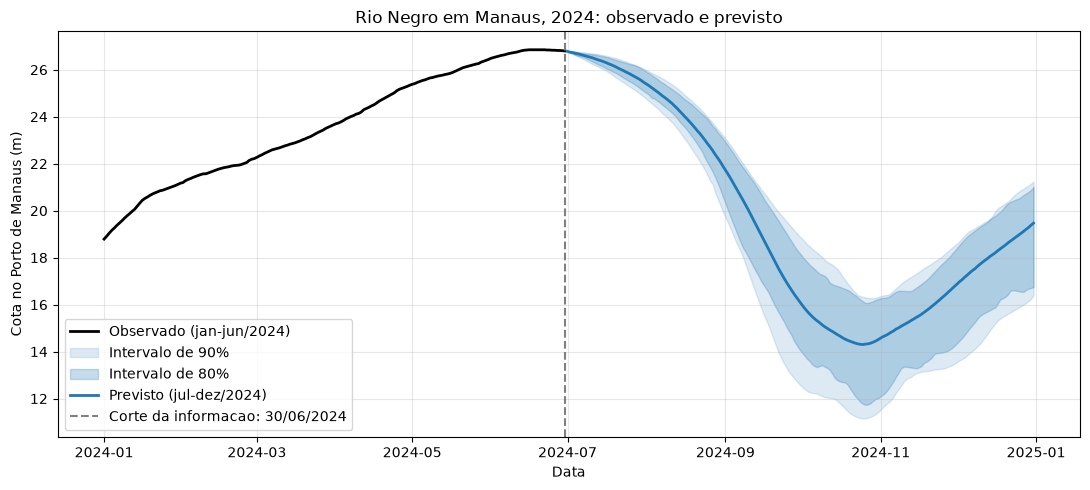

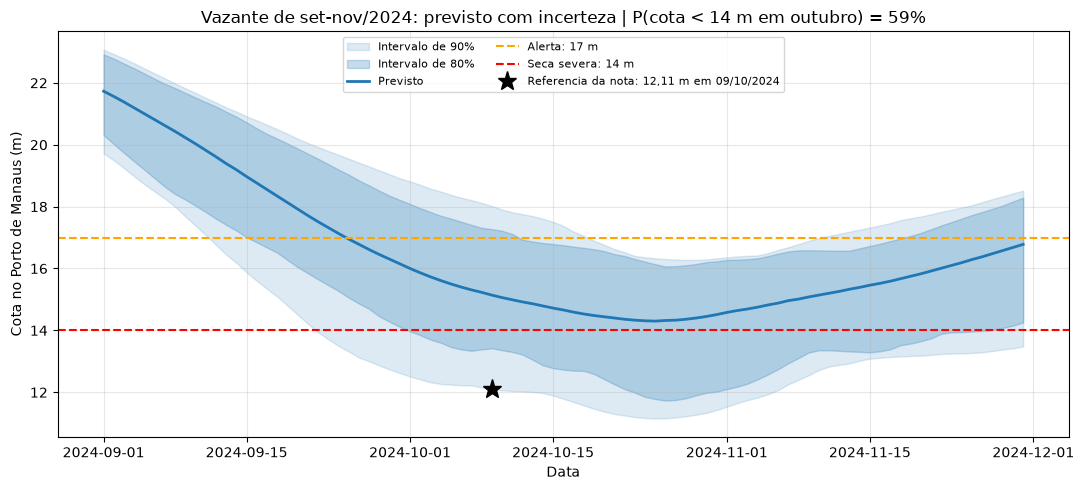

In [ ]:
obs24 = None
if OBS_PATH is not None and Path(OBS_PATH).exists():
    obs24 = pd.read_csv(OBS_PATH, parse_dates=["data"]).set_index("data")["cota"]

jan_jun = train[train["data"] >= "2024-01-01"].set_index("data")["cota"]
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(jan_jun.index, jan_jun.values, color="k", lw=2, label="Observado (jan-jun/2024)")
ax.fill_between(dias, q05, q95, color="C0", alpha=.15, label="Intervalo de 90%")
ax.fill_between(dias, q10, q90, color="C0", alpha=.25, label="Intervalo de 80%")
ax.plot(dias, sub["cota"], color="C0", lw=2, label="Previsto (jul-dez/2024)")
if obs24 is not None:
    ax.plot(obs24.index, obs24.values, color="C3", lw=1.5, label="Observado (jul-dez/2024)")
ax.axvline(pd.Timestamp("2024-06-30"), color="gray", ls="--", label="Corte da informacao: 30/06/2024")
ax.set(xlabel="Data", ylabel="Cota no Porto de Manaus (m)", title="Rio Negro em Manaus, 2024: observado e previsto")
ax.legend(loc="lower left"); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "grafico1_2024.png", dpi=150); plt.show()

m = (dias >= "2024-09-01") & (dias <= "2024-11-30")
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(dias[m], q05[m], q95[m], color="C0", alpha=.15, label="Intervalo de 90%")
ax.fill_between(dias[m], q10[m], q90[m], color="C0", alpha=.25, label="Intervalo de 80%")
ax.plot(dias[m], sub["cota"][m], color="C0", lw=2, label="Previsto")
if obs24 is not None:
    o = obs24[(obs24.index >= "2024-09-01") & (obs24.index <= "2024-11-30")]
    ax.plot(o.index, o.values, color="C3", lw=1.5, label="Observado")
ax.axhline(17, color="orange", ls="--", label="Alerta: 17 m")
ax.axhline(14, color="red", ls="--", label="Seca severa: 14 m")
ax.plot(pd.Timestamp("2024-10-09"), 12.11, marker="*", ms=14, color="k", ls="none", label="Referencia da nota: 12,11 m em 09/10/2024")
ax.set(xlabel="Data", ylabel="Cota no Porto de Manaus (m)",
       title=f"Vazante de set-nov/2024: previsto com incerteza | P(cota < 14 m em outubro) = {p14:.0%}")
ax.legend(loc="upper center", ncol=2, fontsize=8); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "grafico2_vazante.png", dpi=150); plt.show()

## 11. Limitações declaradas
- Os índices climáticos são as séries como estavam publicadas em 2024; valores de anos antigos podem diferir levemente dos publicados na época (revisões retroativas).
- As leituras de 2024 da ANA são brutas; a série histórica mistura dado bruto e consistido (o teste "só bruto" não mudou a conclusão).
- Com 19 anos de validação, as notas do backtest têm erro padrão grande; os conjuntos de variáveis com mais de 4 estações foram descartados por risco de sobreajuste, apesar da nota melhor.
- No período 1995–2004, com poucos anos de treino, o modelo empata com o baseline.
- Todos os experimentos (inclusive os ruins) estão em `outputs/experiments/results.csv`.